# 🏥 CDC Diabetes Health Indicators: Exploratory Data Analysis (EDA)

## Project Overview
Diabetes mellitus is one of the leading causes of morbidity and mortality worldwide. Early risk detection empowers individuals and healthcare providers to implement preventative interventions, lifestyle modifications, and early treatment protocols.

This project utilizes the **CDC Behavioral Risk Factor Surveillance System (BRFSS 2015)** dataset, compiled and curated by Alex Teboul and hosted on the **UC Irvine Machine Learning Repository (ID: 891)**.

### Target Formulation
- **Target Variable**: `Diabetes_binary`
  - `0`: No diabetes
  - `1`: Prediabetes or Diabetes diagnosed by a doctor/healthcare professional

### Objectives of Phase 1 (EDA)
1. **Audit Data Integrity**: Inspect schema, verify zero illegal survey values, assess duplicate profiles.
2. **Characterize Class Imbalance**: Quantify the positive class (~14%) vs negative class (~86%) and establish evaluation metric requirements.
3. **Analyze Clinical & Demographic Distributions**: Evaluate continuous metrics (`BMI`, `PhysHlth`, `MentHlth`), clinical comorbidities (`HighBP`, `HighChol`, `Stroke`), and socioeconomic determinants (`Income`, `Education`, `Age`).
4. **Identify Multicollinearity & Feature Interactions**: Compute correlation matrices, detect collinear features, and uncover compounding risk interactions.
5. **Formulate Preprocessing Roadmap**: Establish strategic guidelines for Phase 2 (resampling, scaling, encoding, and train-test partitioning).

---
## 1. Environment Setup & Library Imports

In this section, we import core data science and statistical packages (`pandas`, `numpy`, `scipy.stats`, `matplotlib`, `seaborn`) and configure operational settings.

In [1]:
import sys
import os
from pathlib import Path
import warnings

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Core numerical & data handling libraries
import pandas as pd
import numpy as np
from scipy import stats

# Advanced visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Print package versions for reproducibility
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")

Pandas version: 3.0.5
NumPy version: 2.5.1
Matplotlib version: 3.11.1
Seaborn version: 0.13.2


### 1.1 Visual Styling & Output Directory Configuration

Setting uniform plotting parameters ensures all charts follow a consistent, publication-quality aesthetic (high DPI, elegant color palettes, legible typography). We also establish `reports/figures/` as our output directory for exported plots.

In [2]:
# Set high-resolution plotting style
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "axes.edgecolor": "#cccccc",
    "axes.linewidth": 0.8,
    "grid.color": "#ebebeb",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
})

# Define figures export directory
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Custom color palettes
PALETTE_BINARY = ["#2b7bba", "#d9534f"]  # Blue for Non-Diabetic, Crimson for Diabetic
PALETTE_GRADIENT = "coolwarm"

print(f"Figure export path initialized at: {FIGURES_DIR.resolve()}")

Figure export path initialized at: D:\Projects\DiabetesPrediction_CDC\reports\figures


---
## 2. Data Ingestion & Schema Inspection

We load the dataset using our modular `src.data_loader` package. If the raw CSV is cached locally at `data/raw/cdc_diabetes_health_indicators.csv`, it is loaded directly; otherwise, it is automatically retrieved from the UC Irvine repository.

In [3]:
# Add project root to Python path
sys.path.append(str(Path("..").resolve()))
from src.data_loader import load_cdc_diabetes_data, get_feature_definitions

# Load dataset
df = load_cdc_diabetes_data(file_path=Path("../data/raw/cdc_diabetes_health_indicators.csv"))
print(f"Dataset successfully loaded with {df.shape[0]:,} records and {df.shape[1]} columns.")

Loading cached dataset from: ..\data\raw\cdc_diabetes_health_indicators.csv


Loaded 253,680 rows and 22 columns.
Dataset successfully loaded with 253,680 records and 22 columns.


### 2.1 Previewing Raw Records

Let's examine the first 5 rows to verify the columns, numeric encodings, and row structure.

In [4]:
# Display first 5 rows
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


### 2.2 Feature Dictionary & Clinical Codebook

To interpret the model's features properly, we examine the metadata and survey questions for all 22 attributes.

In [5]:
# Construct feature codebook summary table
feature_defs = get_feature_definitions()
codebook_rows = []
for col in df.columns:
    meta = feature_defs.get(col, {"description": "N/A", "type": "N/A", "clinical_context": "N/A"})
    codebook_rows.append({
        "Feature": col,
        "Data Type": str(df[col].dtype),
        "Variable Type": meta["type"],
        "Description": meta["description"],
        "Clinical Context": meta["clinical_context"]
    })

codebook_df = pd.DataFrame(codebook_rows)
pd.set_option("display.max_colwidth", None)
codebook_df

,Feature,Data Type,Variable Type,Description,Clinical Context
0,Diabetes_binary,int64,Target (Binary),"0 = No diabetes, 1 = Prediabetes or Diabetes",Primary prediction target derived from CDC BRFSS question: '(Ever told) you have diabetes?'
1,HighBP,int64,Binary,"0 = No high BP, 1 = High BP diagnosed",Adults who have been told by a doctor/nurse they have high blood pressure.
2,HighChol,int64,Binary,"0 = No high cholesterol, 1 = High cholesterol",Adults told they have high blood cholesterol.
3,CholCheck,int64,Binary,"0 = No cholesterol check in 5 years, 1 = Yes",Cholesterol check performed within the past five years.
4,BMI,int64,Continuous,Body Mass Index (kg/m^2),Metric calculated from self-reported height and weight.
5,Smoker,int64,Binary,"0 = No, 1 = Yes",Have you smoked at least 100 cigarettes in your entire life? (5 packs = 100 cigarettes).
6,Stroke,int64,Binary,"0 = No, 1 = Yes","Ever told by a doctor, nurse, or health professional that you had a stroke."
7,HeartDiseaseorAttack,int64,Binary,"0 = No, 1 = Yes",Reported coronary heart disease (CHD) or myocardial infarction (heart attack).
8,PhysActivity,int64,Binary,"0 = No, 1 = Yes",Engaged in physical activity or exercise during past 30 days other than regular job.
9,Fruits,int64,Binary,"0 = No, 1 = Yes",Consume fruit 1 or more times per day.


### 2.3 Structural Schema & Memory Footprint

Checking memory usage, non-null counts, and data types across the dataset.

In [6]:
# Schema and memory summary
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_binary       253680 non-null  int64
 1   HighBP                253680 non-null  int64
 2   HighChol              253680 non-null  int64
 3   CholCheck             253680 non-null  int64
 4   BMI                   253680 non-null  int64
 5   Smoker                253680 non-null  int64
 6   Stroke                253680 non-null  int64
 7   HeartDiseaseorAttack  253680 non-null  int64
 8   PhysActivity          253680 non-null  int64
 9   Fruits                253680 non-null  int64
 10  Veggies               253680 non-null  int64
 11  HvyAlcoholConsump     253680 non-null  int64
 12  AnyHealthcare         253680 non-null  int64
 13  NoDocbcCost           253680 non-null  int64
 14  GenHlth               253680 non-null  int64
 15  MentHlth              253680 non-null  int64


---
## 3. Data Hygiene & Integrity Audit

Before diving into distributions, we must verify the statistical hygiene of the raw data:
1. Are there any missing or NaN values?
2. Are there duplicated respondent records, and what is their clinical significance?
3. Are all numeric values within legitimate survey ranges?

### 3.1 Missing Value Verification

Evaluating null counts across all 22 columns.

In [7]:
# Check for missing values
null_counts = df.isnull().sum()
print("Missing values per column:")
if (null_counts > 0).any():
    print(null_counts[null_counts > 0])
else:
    print("Zero missing values across all 22 columns! Data completeness is 100%.")

Missing values per column:
Zero missing values across all 22 columns! Data completeness is 100%.


### 3.2 Duplicate Record Analysis

In large population surveys with discrete, binned categorical variables (e.g. 13 age categories, binary yes/no answers, 8 income brackets), multiple respondents can independently provide identical answers. Let's quantify duplicate occurrences.

In [8]:
# Count duplicate rows
num_duplicates = df.duplicated().sum()
pct_duplicates = (num_duplicates / len(df)) * 100
print(f"Total duplicate rows: {num_duplicates:,} ({pct_duplicates:.2f}% of dataset)")

# Preview sample of duplicate rows
duplicate_samples = df[df.duplicated(keep=False)].sort_values(by=list(df.columns[:5])).head(6)
duplicate_samples

Total duplicate rows: 24,206 (9.54% of dataset)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
4517,0,0,0,0,17,0,0,0,1,1,...,1,0,1,0,0,0,0,8,6,8
207307,0,0,0,0,17,0,0,0,1,1,...,1,0,1,0,0,0,0,8,6,8
42369,0,0,0,0,18,0,0,0,1,1,...,1,0,1,0,0,0,0,10,6,8
108949,0,0,0,0,18,0,0,0,1,1,...,1,0,1,0,0,0,0,10,6,8
17475,0,0,0,0,19,0,0,0,1,1,...,1,0,1,0,0,0,0,4,6,8
48850,0,0,0,0,19,0,0,0,1,1,...,1,0,2,0,0,0,0,9,6,8


> [!NOTE]
> **Clinical & Statistical Interpretation of Duplicates**:
> In a questionnaire of 21 multiple-choice questions across 253,680 people, shared combinations of answers (such as non-smoking, non-drinking, young adults without hypertension or cholesterol issues) represent identical real-world demographic profiles. Removing them would artificially distort real-world population proportions. We retain them intact for training and validation.

### 3.3 Domain Validity & Boundary Check

Verifying that all continuous, ordinal, and binary features fall strictly within legal BRFSS bounds.

In [9]:
# Check min, max, and unique count for each feature
range_audit = pd.DataFrame({
    "Min": df.min(),
    "Max": df.max(),
    "Unique_Values": df.nunique(),
    "Dtype": df.dtypes
})
range_audit

,Min,Max,Unique_Values,Dtype
Diabetes_binary,0,1,2,int64
HighBP,0,1,2,int64
HighChol,0,1,2,int64
CholCheck,0,1,2,int64
BMI,12,98,84,int64
Smoker,0,1,2,int64
Stroke,0,1,2,int64
HeartDiseaseorAttack,0,1,2,int64
PhysActivity,0,1,2,int64
Fruits,0,1,2,int64


---
## 4. Target Variable Analysis: `Diabetes_binary`

The target variable indicates whether a respondent has been diagnosed with prediabetes or diabetes (`1`) or has no diabetes (`0`). Let's examine the raw counts and percentage share.

In [10]:
# Target frequency and percentage breakdown
target_counts = df["Diabetes_binary"].value_counts()
target_pct = df["Diabetes_binary"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Class": ["No Diabetes (0)", "Diabetes / Prediabetes (1)"],
    "Count": target_counts.values,
    "Percentage (%)": target_pct.round(2).values
}).set_index("Class")
target_summary

,Count,Percentage (%)
Class,,
No Diabetes (0),218334,86.07
Diabetes / Prediabetes (1),35346,13.93


### 4.1 Visualizing Target Class Imbalance

We visualize the class distribution using a side-by-side Donut Chart and an annotated Bar Plot.

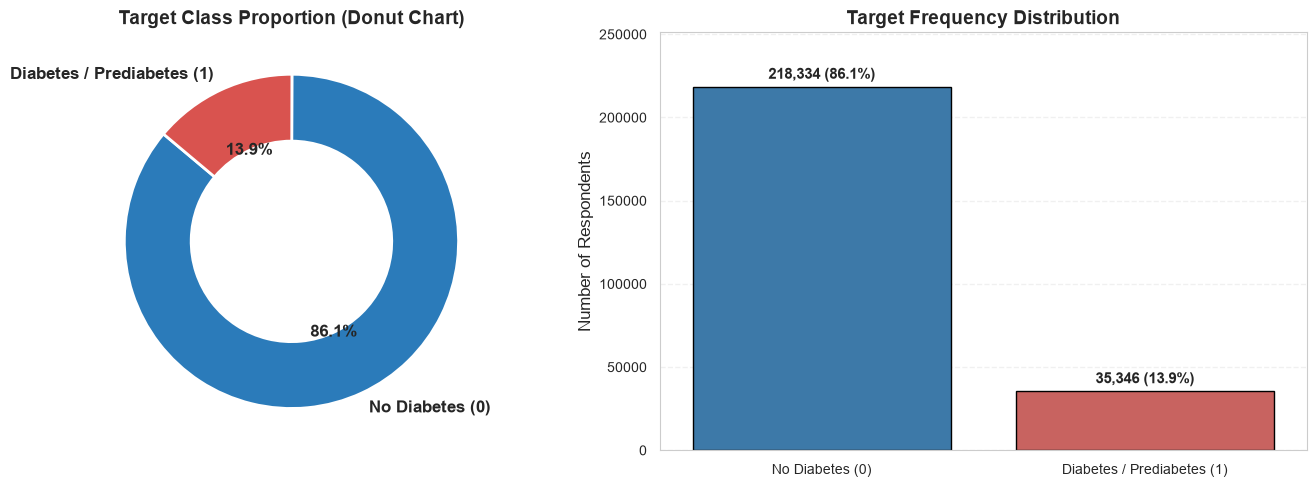

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Donut Chart
axes[0].pie(
    target_counts,
    labels=["No Diabetes (0)", "Diabetes / Prediabetes (1)"],
    autopct="%1.1f%%",
    startangle=140,
    colors=PALETTE_BINARY,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[0].set_title("Target Class Proportion (Donut Chart)", fontsize=14, weight='bold')

# Bar Plot with annotations
bars = sns.barplot(
    x=["No Diabetes (0)", "Diabetes / Prediabetes (1)"],
    y=target_counts.values,
    palette=PALETTE_BINARY,
    ax=axes[1],
    edgecolor="black",
    linewidth=1
)
for bar in bars.patches:
    y_val = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        y_val + 3000,
        f"{int(y_val):,} ({y_val/len(df)*100:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        weight="bold"
    )

axes[1].set_title("Target Frequency Distribution", fontsize=14, weight='bold')
axes[1].set_ylabel("Number of Respondents", fontsize=12)
axes[1].set_ylim(0, max(target_counts.values) * 1.15)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

> [!IMPORTANT]
> **Key Machine Learning Takeaways**:
> 1. **Class Imbalance Ratio**: Approximately **86.1% (Non-Diabetic)** to **13.9% (Diabetic)** — roughly a 6.2 : 1 imbalance.
> 2. **Pitfall of Accuracy**: A naive baseline classifier predicting `0` for every patient achieves 86.07% accuracy while failing 100% of diabetes patients.
> 3. **Metric Selection**: Models must be evaluated using **Precision-Recall AUC (PR-AUC)**, **Recall (Sensitivity)**, **F1-Score**, and **ROC-AUC**, rather than standard accuracy.
> 4. **Balancing Strategies**: During Phase 2, we will test `class_weight='balanced'`, focal loss, threshold tuning, and SMOTE / undersampling.

---
## 5. Continuous & Health Scale Variables: `BMI`, `MentHlth`, `PhysHlth`

Now we analyze the continuous and count variables:
- `BMI`: Body Mass Index ($kg/m^2$)
- `MentHlth`: Days of poor mental health in past 30 days (0-30)
- `PhysHlth`: Days of physical illness or injury in past 30 days (0-30)

In [12]:
# Summary statistics for continuous and count variables
cont_cols = ["BMI", "MentHlth", "PhysHlth"]
cont_stats = df[cont_cols].describe().T
cont_stats["IQR"] = cont_stats["75%"] - cont_stats["25%"]
cont_stats["Skewness"] = df[cont_cols].skew()
cont_stats["Kurtosis"] = df[cont_cols].kurt()
cont_stats[["mean", "std", "min", "25%", "50%", "75%", "max", "IQR", "Skewness", "Kurtosis"]].round(2)

,mean,std,min,25%,50%,75%,max,IQR,Skewness,Kurtosis
BMI,28.38,6.61,12.0,24.0,27.0,31.0,98.0,7.0,2.12,11.00
MentHlth,3.18,7.41,0.0,0.0,0.0,2.0,30.0,2.0,2.72,6.44
PhysHlth,4.24,8.72,0.0,0.0,0.0,3.0,30.0,3.0,2.21,3.50


### 5.1 Distribution of Body Mass Index (BMI)

We inspect the BMI distribution and overlay clinical BMI classification thresholds defined by the World Health Organization and CDC:
- **Underweight**: $< 18.5$
- **Normal weight**: $18.5 - 24.9$
- **Overweight**: $25.0 - 29.9$
- **Obese**: $\ge 30.0$

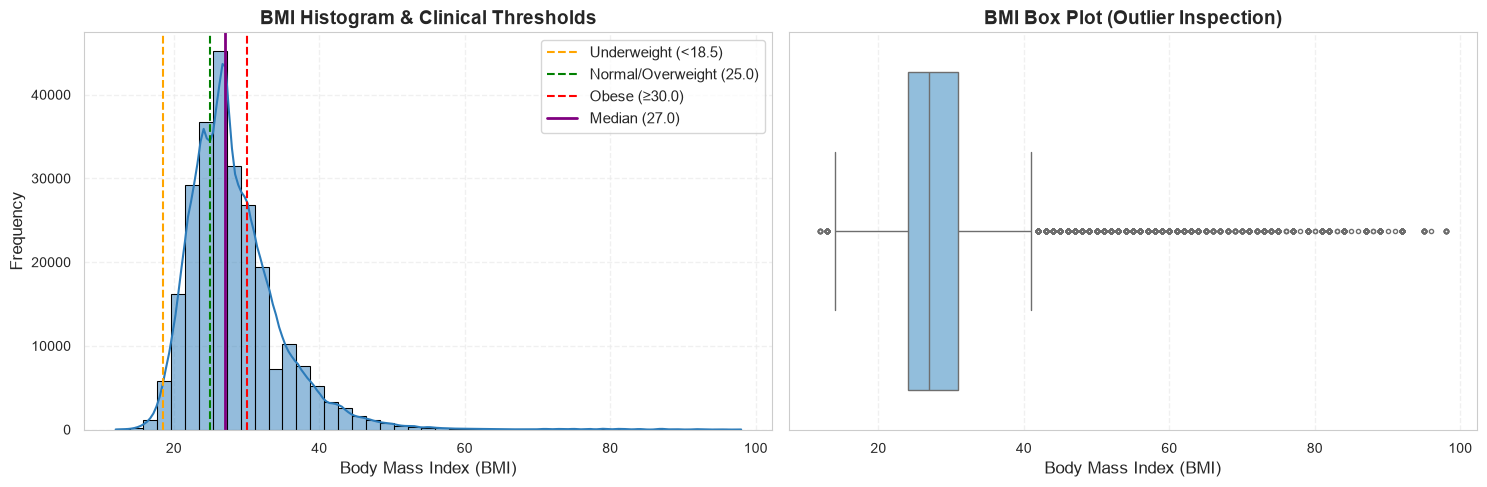

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram with KDE
sns.histplot(
    data=df,
    x="BMI",
    bins=45,
    kde=True,
    color="#2b7bba",
    ax=axes[0],
    edgecolor="black"
)
axes[0].axvline(18.5, color="orange", linestyle="--", linewidth=1.5, label="Underweight (<18.5)")
axes[0].axvline(25.0, color="green", linestyle="--", linewidth=1.5, label="Normal/Overweight (25.0)")
axes[0].axvline(30.0, color="red", linestyle="--", linewidth=1.5, label="Obese (≥30.0)")
axes[0].axvline(df["BMI"].median(), color="purple", linestyle="-", linewidth=2, label=f"Median ({df['BMI'].median():.1f})")
axes[0].set_title("BMI Histogram & Clinical Thresholds", fontsize=14, weight="bold")
axes[0].set_xlabel("Body Mass Index (BMI)")
axes[0].set_ylabel("Frequency")
axes[0].legend(loc="upper right")

# Box Plot
sns.boxplot(
    data=df,
    x="BMI",
    color="#85c1e9",
    ax=axes[1],
    fliersize=3
)
axes[1].set_title("BMI Box Plot (Outlier Inspection)", fontsize=14, weight="bold")
axes[1].set_xlabel("Body Mass Index (BMI)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_bmi_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.2 Physical and Mental Health Unhealthy Days

Inspecting `PhysHlth` and `MentHlth` distributions to understand the degree of zero-inflation.

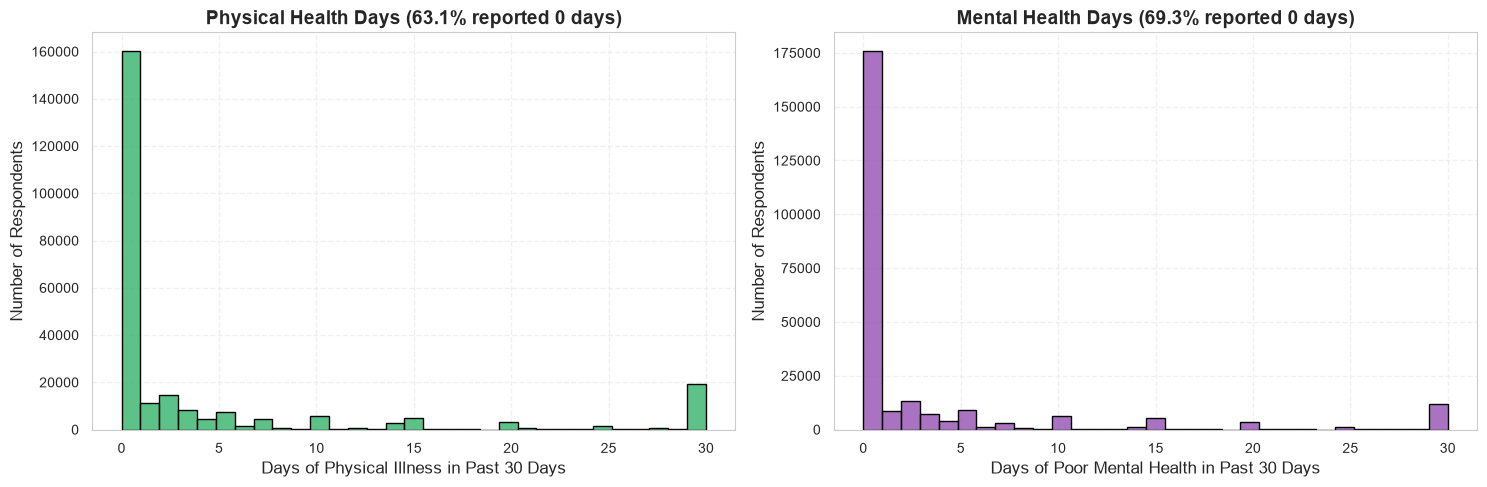

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# PhysHlth Distribution
sns.histplot(
    data=df,
    x="PhysHlth",
    bins=31,
    color="#27ae60",
    ax=axes[0],
    edgecolor="black"
)
zero_phys = (df["PhysHlth"] == 0).mean() * 100
axes[0].set_title(f"Physical Health Days ({zero_phys:.1f}% reported 0 days)", fontsize=14, weight="bold")
axes[0].set_xlabel("Days of Physical Illness in Past 30 Days")
axes[0].set_ylabel("Number of Respondents")

# MentHlth Distribution
sns.histplot(
    data=df,
    x="MentHlth",
    bins=31,
    color="#8e44ad",
    ax=axes[1],
    edgecolor="black"
)
zero_ment = (df["MentHlth"] == 0).mean() * 100
axes[1].set_title(f"Mental Health Days ({zero_ment:.1f}% reported 0 days)", fontsize=14, weight="bold")
axes[1].set_xlabel("Days of Poor Mental Health in Past 30 Days")
axes[1].set_ylabel("Number of Respondents")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_mental_physical_health.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.3 BMI Stratified by Diabetes Status

Comparing BMI distributions between respondents with vs without diabetes using Violin and Box plots.

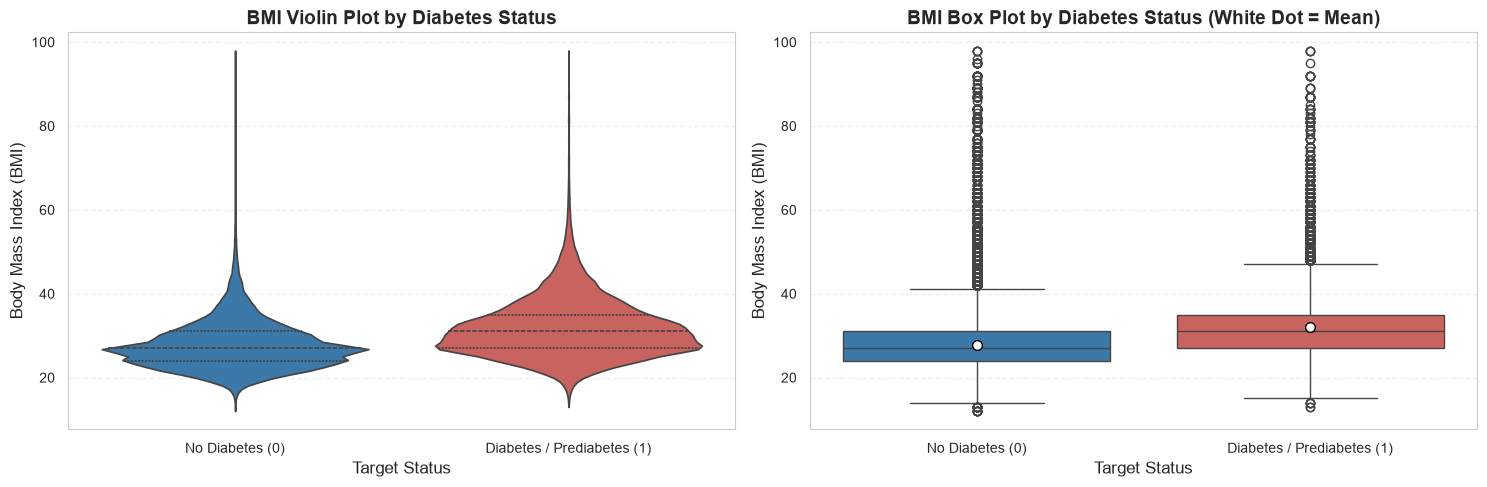

BMI Statistics by Diabetes Status:
                  count   mean  median   std
Diabetes_binary                             
0                218334  27.81    27.0  6.29
1                 35346  31.94    31.0  7.36


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Violin Plot
sns.violinplot(
    data=df,
    x="Diabetes_binary",
    y="BMI",
    palette=PALETTE_BINARY,
    ax=axes[0],
    inner="quartile",
    cut=0
)
axes[0].set_xticklabels(["No Diabetes (0)", "Diabetes / Prediabetes (1)"])
axes[0].set_title("BMI Violin Plot by Diabetes Status", fontsize=14, weight="bold")
axes[0].set_xlabel("Target Status")
axes[0].set_ylabel("Body Mass Index (BMI)")

# Box Plot
sns.boxplot(
    data=df,
    x="Diabetes_binary",
    y="BMI",
    palette=PALETTE_BINARY,
    ax=axes[1],
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": "7"}
)
axes[1].set_xticklabels(["No Diabetes (0)", "Diabetes / Prediabetes (1)"])
axes[1].set_title("BMI Box Plot by Diabetes Status (White Dot = Mean)", fontsize=14, weight="bold")
axes[1].set_xlabel("Target Status")
axes[1].set_ylabel("Body Mass Index (BMI)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_bmi_vs_diabetes.png", dpi=300, bbox_inches="tight")
plt.show()

# Mean and Median numerical comparison
bmi_comp = df.groupby("Diabetes_binary")["BMI"].agg(["count", "mean", "median", "std"]).round(2)
print("BMI Statistics by Diabetes Status:")
print(bmi_comp)

---
## 6. Demographic & Socioeconomic Risk Factors

In this section, we decode encoded survey integers into human-readable categories to examine:
- `Age`: 13 discrete age brackets
- `Sex`: Female (`0`) vs Male (`1`)
- `Education`: 6 attainment tiers
- `Income`: 8 household income tiers

In [16]:
from src.eda_utils import AGE_LABELS, EDUCATION_LABELS, INCOME_LABELS, SEX_LABELS, GEN_HLTH_LABELS

# Create decoded working dataframe for intuitive visualizations
df_viz = df.copy()
df_viz["Age_Group"] = df_viz["Age"].map(AGE_LABELS)
df_viz["Education_Level"] = df_viz["Education"].map(EDUCATION_LABELS)
df_viz["Income_Bracket"] = df_viz["Income"].map(INCOME_LABELS)
df_viz["Sex_Label"] = df_viz["Sex"].map(SEX_LABELS)
df_viz["GenHlth_Label"] = df_viz["GenHlth"].map(GEN_HLTH_LABELS)

print("Decoded categories successfully created for visualization.")

Decoded categories successfully created for visualization.


### 6.1 Age Gradient in Diabetes Prevalence

We examine how the risk of diabetes escalates across the 13 age categories.

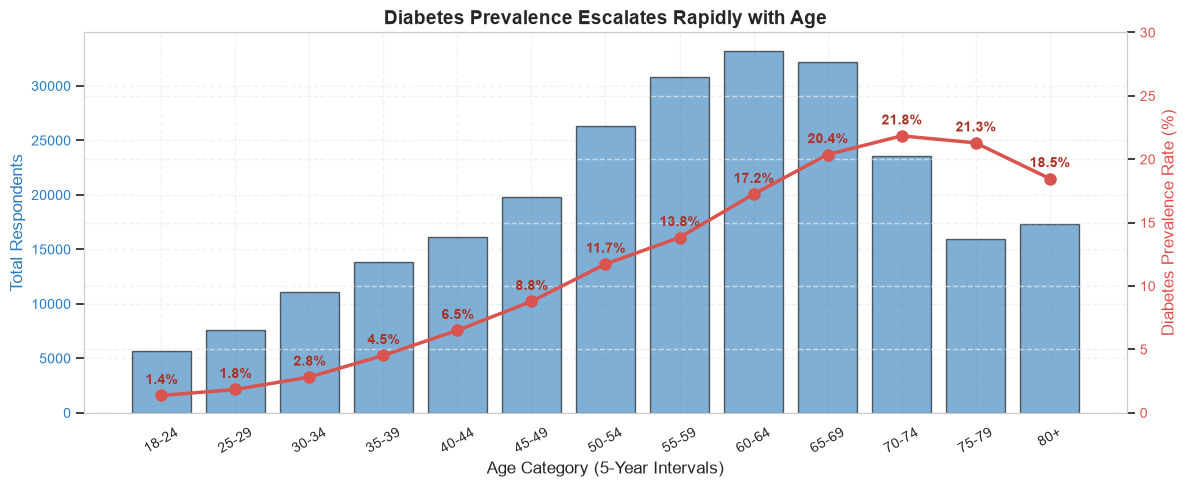

In [17]:
age_agg = df.groupby("Age")["Diabetes_binary"].agg(
    Total="count",
    Diabetic="sum"
).reset_index()
age_agg["Prevalence_Pct"] = (age_agg["Diabetic"] / age_agg["Total"]) * 100
age_agg["Age_Group"] = age_agg["Age"].map(AGE_LABELS)

fig, ax1 = plt.subplots(figsize=(12, 5))

# Bar chart of population volume
color = "#2b7bba"
bars = ax1.bar(age_agg["Age_Group"], age_agg["Total"], color=color, alpha=0.6, edgecolor="black", label="Survey Respondents")
ax1.set_xlabel("Age Category (5-Year Intervals)", fontsize=12)
ax1.set_ylabel("Total Respondents", color=color, fontsize=12)
ax1.tick_params(axis="y", labelcolor=color)
ax1.set_xticklabels(age_agg["Age_Group"], rotation=30)

# Line chart for prevalence rate
ax2 = ax1.twinx()
color2 = "#d9534f"
line = ax2.plot(age_agg["Age_Group"], age_agg["Prevalence_Pct"], color=color2, marker="o", linewidth=2.5, markersize=8, label="Diabetes Prevalence (%)")
ax2.set_ylabel("Diabetes Prevalence Rate (%)", color=color2, fontsize=12)
ax2.tick_params(axis="y", labelcolor=color2)
ax2.set_ylim(0, 30)

# Annotate prevalence percentages
for i, txt in enumerate(age_agg["Prevalence_Pct"]):
    ax2.annotate(f"{txt:.1f}%", (i, txt + 0.9), ha="center", fontsize=10, weight="bold", color="#a93226")

plt.title("Diabetes Prevalence Escalates Rapidly with Age", fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_age_vs_diabetes.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.2 Gender Disparity Analysis

Examining diabetes rates and sample composition across biological sex.

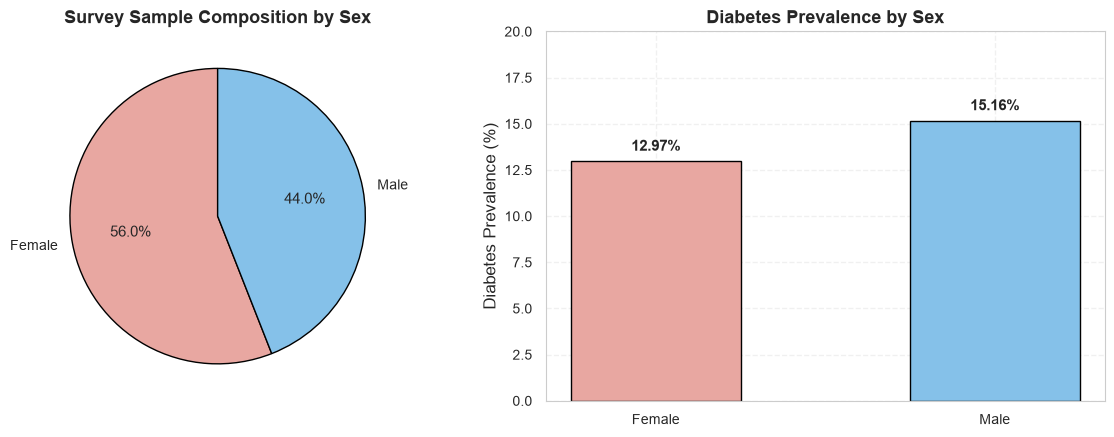

In [18]:
sex_agg = df.groupby("Sex")["Diabetes_binary"].agg(
    Total="count",
    Diabetic="sum"
).reset_index()
sex_agg["Prevalence_Pct"] = (sex_agg["Diabetic"] / sex_agg["Total"]) * 100
sex_agg["Sex_Label"] = sex_agg["Sex"].map(SEX_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gender sample composition
axes[0].pie(
    sex_agg["Total"],
    labels=sex_agg["Sex_Label"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#e8a7a1", "#85c1e9"],
    wedgeprops=dict(edgecolor="black", linewidth=1)
)
axes[0].set_title("Survey Sample Composition by Sex", fontsize=13, weight="bold")

# Diabetes prevalence rate by sex
bars = axes[1].bar(
    sex_agg["Sex_Label"],
    sex_agg["Prevalence_Pct"],
    color=["#e8a7a1", "#85c1e9"],
    edgecolor="black",
    width=0.5
)
for bar in bars:
    y_val = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        y_val + 0.4,
        f"{y_val:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        weight="bold"
    )
axes[1].set_ylabel("Diabetes Prevalence (%)")
axes[1].set_ylim(0, 20)
axes[1].set_title("Diabetes Prevalence by Sex", fontsize=13, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_sex_vs_diabetes.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.3 Socioeconomic Determinants: Education and Income Gradients

Investigating how diabetes rates inversely track educational attainment and household income.

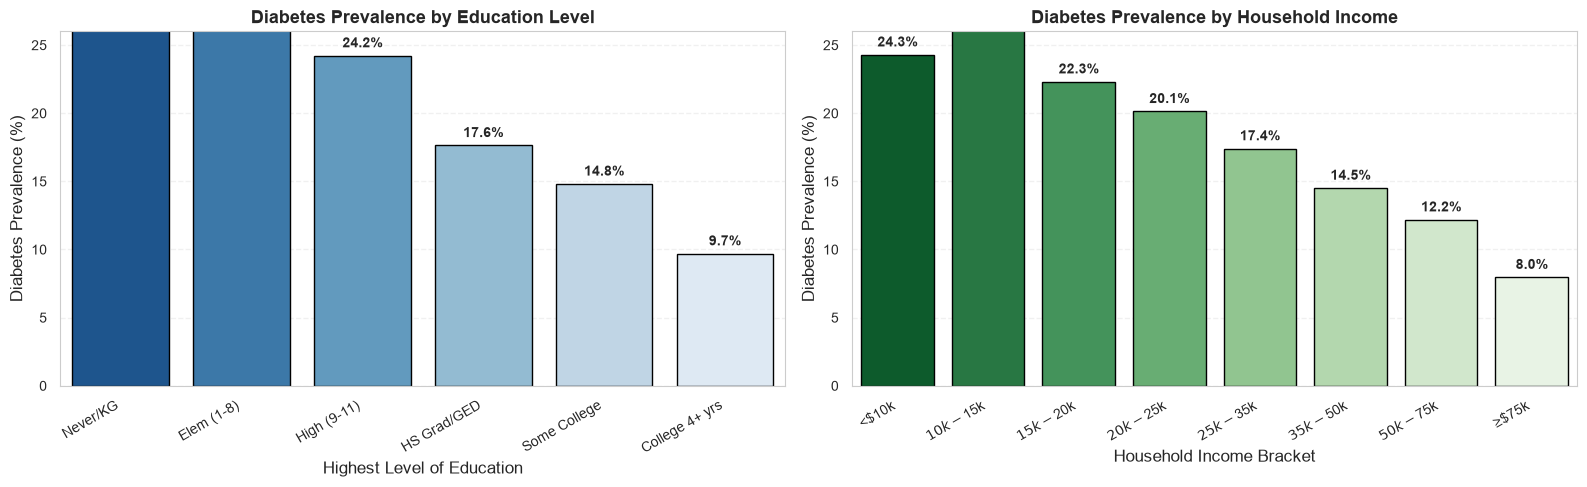

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Education gradient
edu_order = [EDUCATION_LABELS[i] for i in range(1, 7)]
edu_agg = df_viz.groupby("Education_Level")["Diabetes_binary"].mean().reindex(edu_order) * 100
bars1 = sns.barplot(x=edu_agg.index, y=edu_agg.values, palette="Blues_r", ax=axes[0], edgecolor="black")
axes[0].set_title("Diabetes Prevalence by Education Level", fontsize=13, weight="bold")
axes[0].set_xlabel("Highest Level of Education")
axes[0].set_ylabel("Diabetes Prevalence (%)")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right")
for p in bars1.patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.4),
                     ha="center", va="bottom", fontsize=10, weight="bold")
axes[0].set_ylim(0, 26)

# Income gradient
inc_order = [INCOME_LABELS[i] for i in range(1, 9)]
inc_agg = df_viz.groupby("Income_Bracket")["Diabetes_binary"].mean().reindex(inc_order) * 100
bars2 = sns.barplot(x=inc_agg.index, y=inc_agg.values, palette="Greens_r", ax=axes[1], edgecolor="black")
axes[1].set_title("Diabetes Prevalence by Household Income", fontsize=13, weight="bold")
axes[1].set_xlabel("Household Income Bracket")
axes[1].set_ylabel("Diabetes Prevalence (%)")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha="right")
for p in bars2.patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.4),
                     ha="center", va="bottom", fontsize=10, weight="bold")
axes[1].set_ylim(0, 26)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_socioeconomic_gradient.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 7. Clinical Comorbidities & Chronic Illness Clustering

Diabetes rarely occurs in isolation; it is deeply intertwined with cardiovascular diseases and metabolic dysfunction. We assess:
- `HighBP`: Diagnosed Hypertension
- `HighChol`: Diagnosed Hypercholesterolemia
- `CholCheck`: Cholesterol check within 5 years
- `Stroke`: History of Stroke
- `HeartDiseaseorAttack`: History of Coronary Heart Disease or Myocardial Infarction

In [20]:
comorbidities = ["HighBP", "HighChol", "CholCheck", "Stroke", "HeartDiseaseorAttack"]
comorb_records = []

for c in comorbidities:
    c_ct = pd.crosstab(df[c], df["Diabetes_binary"], normalize="index") * 100
    prev_no = c_ct.loc[0, 1] if 0 in c_ct.index else 0
    prev_yes = c_ct.loc[1, 1] if 1 in c_ct.index else 0
    rr = prev_yes / prev_no if prev_no > 0 else np.nan
    comorb_records.append({
        "Condition": c,
        "Prevalence in Condition=0 (%)": round(prev_no, 2),
        "Prevalence in Condition=1 (%)": round(prev_yes, 2),
        "Relative Risk (RR)": round(rr, 2)
    })

comorb_table = pd.DataFrame(comorb_records)
comorb_table

,Condition,Prevalence in Condition=0 (%),Prevalence in Condition=1 (%),Relative Risk (RR)
0,HighBP,6.04,24.45,4.05
1,HighChol,7.98,22.01,2.76
2,CholCheck,2.54,14.37,5.65
3,Stroke,13.18,31.75,2.41
4,HeartDiseaseorAttack,11.95,32.97,2.76


### 7.1 Visualizing Clinical Comorbidity Rates Between Cohorts

Comparing the presence of clinical conditions in Diabetic vs Non-Diabetic populations.

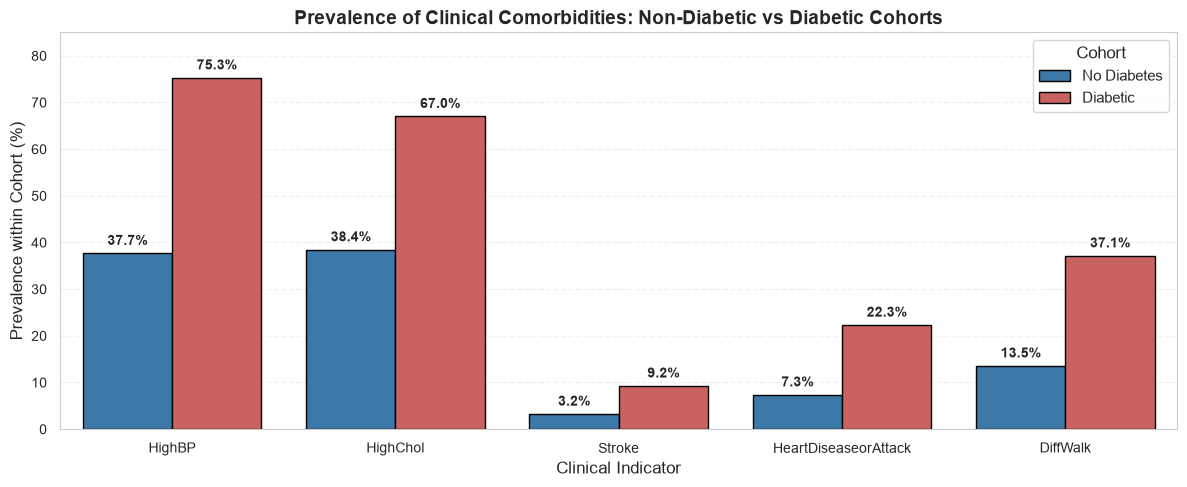

In [21]:
comp_data = []
for c in ["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]:
    rates = df.groupby("Diabetes_binary")[c].mean() * 100
    comp_data.append({
        "Condition": c,
        "No Diabetes": rates[0],
        "Diabetic": rates[1]
    })

comp_df = pd.DataFrame(comp_data).melt(id_vars="Condition", var_name="Cohort", value_name="Prevalence_Pct")

plt.figure(figsize=(12, 5))
ax = sns.barplot(
    data=comp_df,
    x="Condition",
    y="Prevalence_Pct",
    hue="Cohort",
    palette=PALETTE_BINARY,
    edgecolor="black"
)
plt.title("Prevalence of Clinical Comorbidities: Non-Diabetic vs Diabetic Cohorts", fontsize=14, weight="bold")
plt.ylabel("Prevalence within Cohort (%)")
plt.xlabel("Clinical Indicator")
plt.ylim(0, 85)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1.2),
                    ha="center", va="bottom", fontsize=10, weight="bold")

plt.legend(title="Cohort")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_clinical_comorbidities.png", dpi=300, bbox_inches="tight")
plt.show()

### 7.2 Multi-Comorbidity Escalation Index

We compute a compound comorbidity score summing `HighBP`, `HighChol`, `HeartDiseaseorAttack`, and `Stroke` (0 to 4 conditions) to quantify how multi-morbidity accelerates diabetes risk.

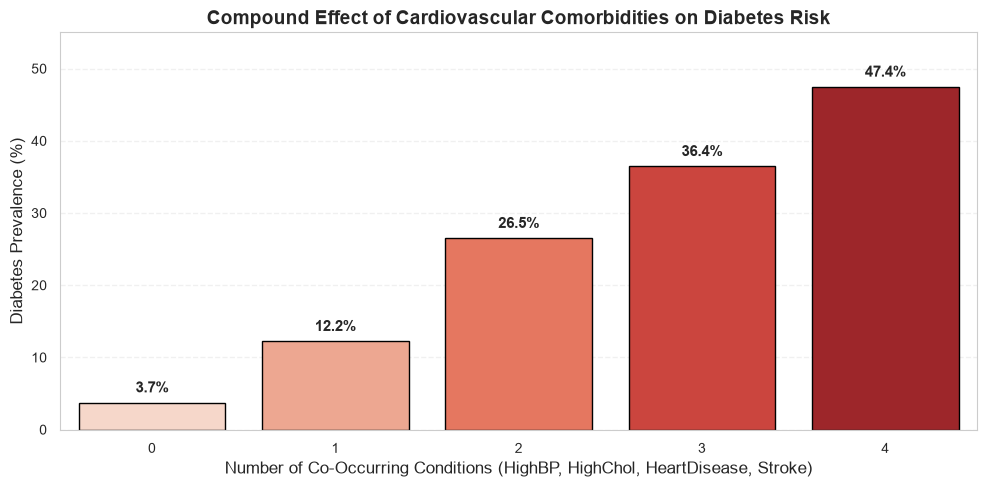

In [22]:
# Construct multi-comorbidity count index
df["Comorbidity_Score"] = df[["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]].sum(axis=1)

score_agg = df.groupby("Comorbidity_Score")["Diabetes_binary"].agg(
    Total="count",
    Diabetic="sum"
).reset_index()
score_agg["Prevalence_Pct"] = (score_agg["Diabetic"] / score_agg["Total"]) * 100

plt.figure(figsize=(10, 5))
bars = sns.barplot(
    data=score_agg,
    x="Comorbidity_Score",
    y="Prevalence_Pct",
    palette="Reds",
    edgecolor="black"
)
plt.title("Compound Effect of Cardiovascular Comorbidities on Diabetes Risk", fontsize=14, weight="bold")
plt.xlabel("Number of Co-Occurring Conditions (HighBP, HighChol, HeartDisease, Stroke)")
plt.ylabel("Diabetes Prevalence (%)")
plt.ylim(0, 55)

for bar in bars.patches:
    y_val = bar.get_height()
    bars.annotate(f"{y_val:.1f}%", (bar.get_x() + bar.get_width() / 2, y_val + 1),
                  ha="center", va="bottom", fontsize=11, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_comorbidity_escalation.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 8. Lifestyle, Diet, and Functional Mobility Indicators

Examining behavioral factors and their association with diabetes rates:
- `PhysActivity`: Physical activity in past 30 days
- `Fruits`: Consume fruit $\ge 1$ time/day
- `Veggies`: Consume vegetables $\ge 1$ time/day
- `Smoker`: Smoked at least 100 cigarettes lifetime
- `HvyAlcoholConsump`: Heavy drinking criteria
- `DiffWalk`: Serious difficulty walking or climbing stairs

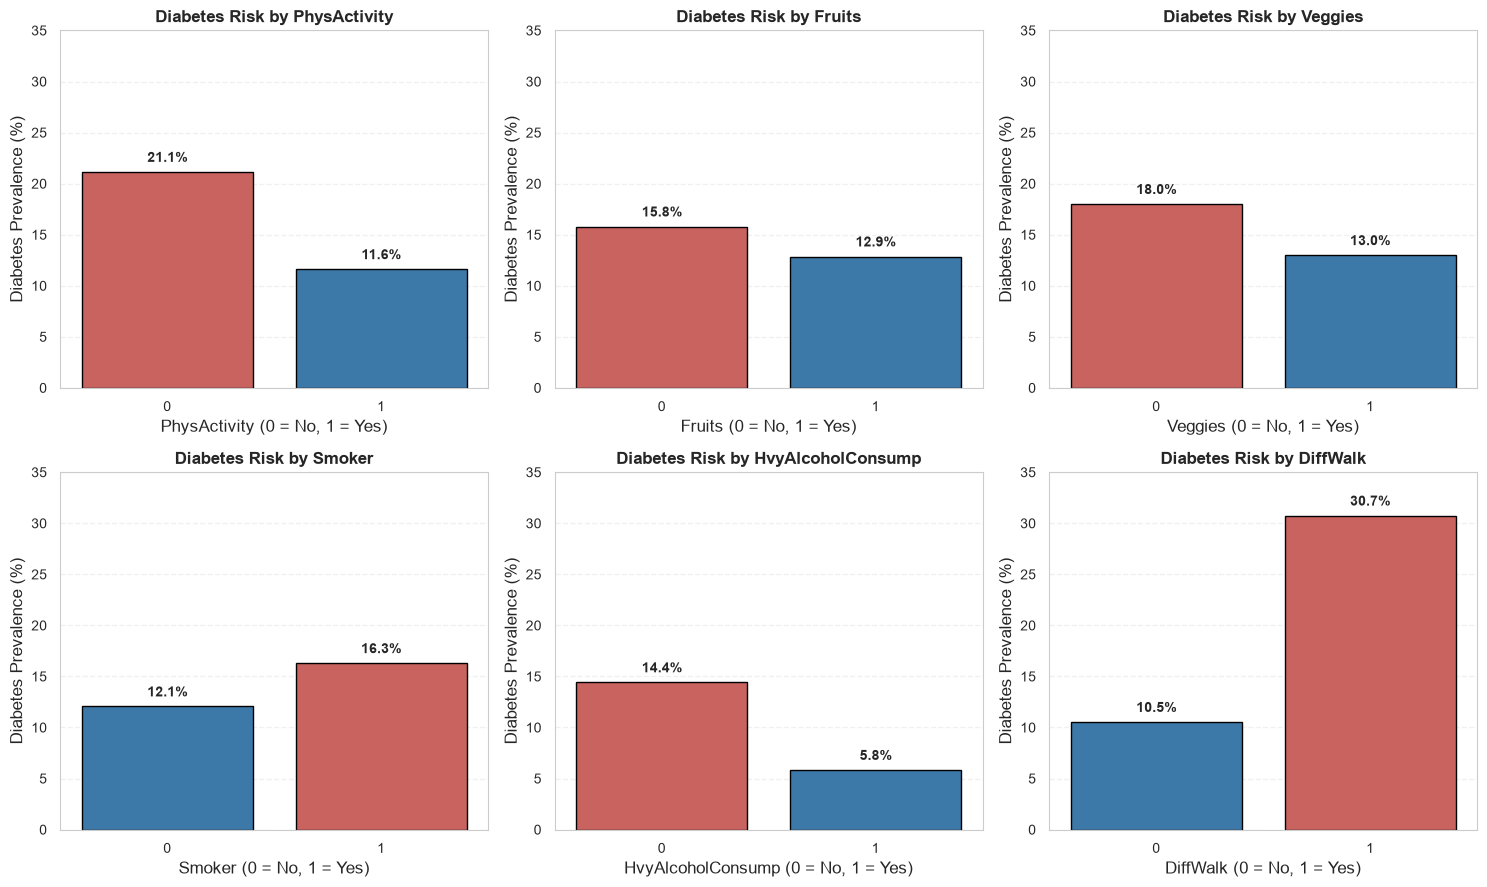

In [23]:
lifestyle_factors = ["PhysActivity", "Fruits", "Veggies", "Smoker", "HvyAlcoholConsump", "DiffWalk"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, col in enumerate(lifestyle_factors):
    sub_agg = df.groupby(col)["Diabetes_binary"].mean() * 100
    palette = ["#2b7bba", "#d9534f"] if col in ["Smoker", "DiffWalk"] else ["#d9534f", "#2b7bba"]
    bars = sns.barplot(x=sub_agg.index, y=sub_agg.values, ax=axes[idx], palette=palette, edgecolor="black")
    axes[idx].set_title(f"Diabetes Risk by {col}", fontsize=12, weight="bold")
    axes[idx].set_ylabel("Diabetes Prevalence (%)")
    axes[idx].set_xlabel(f"{col} (0 = No, 1 = Yes)")
    axes[idx].set_ylim(0, 35)
    for p in bars.patches:
        axes[idx].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.7),
                           ha="center", va="bottom", fontsize=10, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_lifestyle_mobility.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 9. Correlation & Multicollinearity Analysis

In this section, we examine linear and rank correlations across all 21 features and the target to:
1. Identify the strongest individual predictors of diabetes.
2. Check for multicollinearity among survey questions (e.g. general health vs physical health).

In [24]:
# Compute Pearson correlation matrix
corr_matrix = df.drop(columns=["Comorbidity_Score"], errors="ignore").corr()
target_corr = corr_matrix["Diabetes_binary"].drop("Diabetes_binary").sort_values(ascending=False)

target_corr_df = pd.DataFrame({
    "Pearson_Correlation (r)": target_corr.round(4)
})
target_corr_df

,Pearson_Correlation (r)
GenHlth,0.2936
HighBP,0.2631
DiffWalk,0.2183
BMI,0.2168
HighChol,0.2003
Age,0.1774
HeartDiseaseorAttack,0.1773
PhysHlth,0.1713
Stroke,0.1058
MentHlth,0.0693


### 9.1 Ranking Top Predictors by Correlation with Diabetes

Visualizing all 21 survey features ranked by their correlation with `Diabetes_binary`.

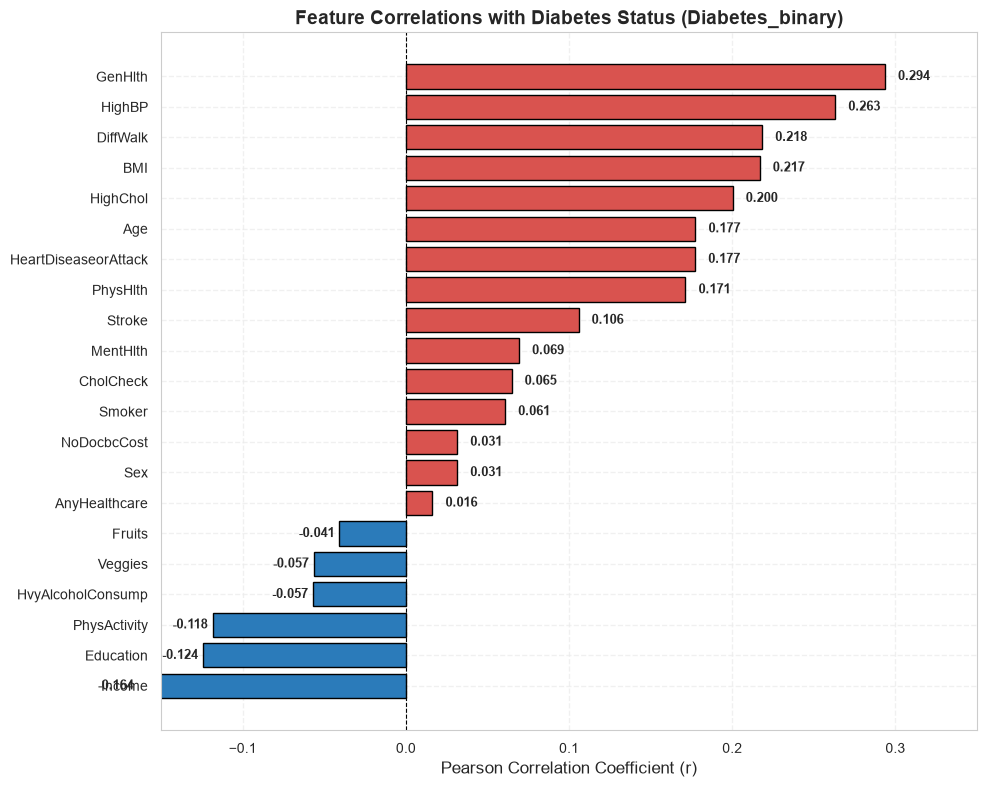

In [25]:
plt.figure(figsize=(10, 8))
colors = ["#d9534f" if val > 0 else "#2b7bba" for val in target_corr.values]
bars = plt.barh(target_corr.index[::-1], target_corr.values[::-1], color=colors[::-1], edgecolor="black")
plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Feature Correlations with Diabetes Status (Diabetes_binary)", fontsize=14, weight="bold")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.xlim(-0.15, 0.35)

# Annotate correlation values
for bar in bars:
    w = bar.get_width()
    offset = 0.008 if w >= 0 else -0.025
    plt.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=9, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_feature_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

### 9.2 Complete Predictor Correlation Heatmap

Evaluating cross-correlations across all pairs of survey indicators.

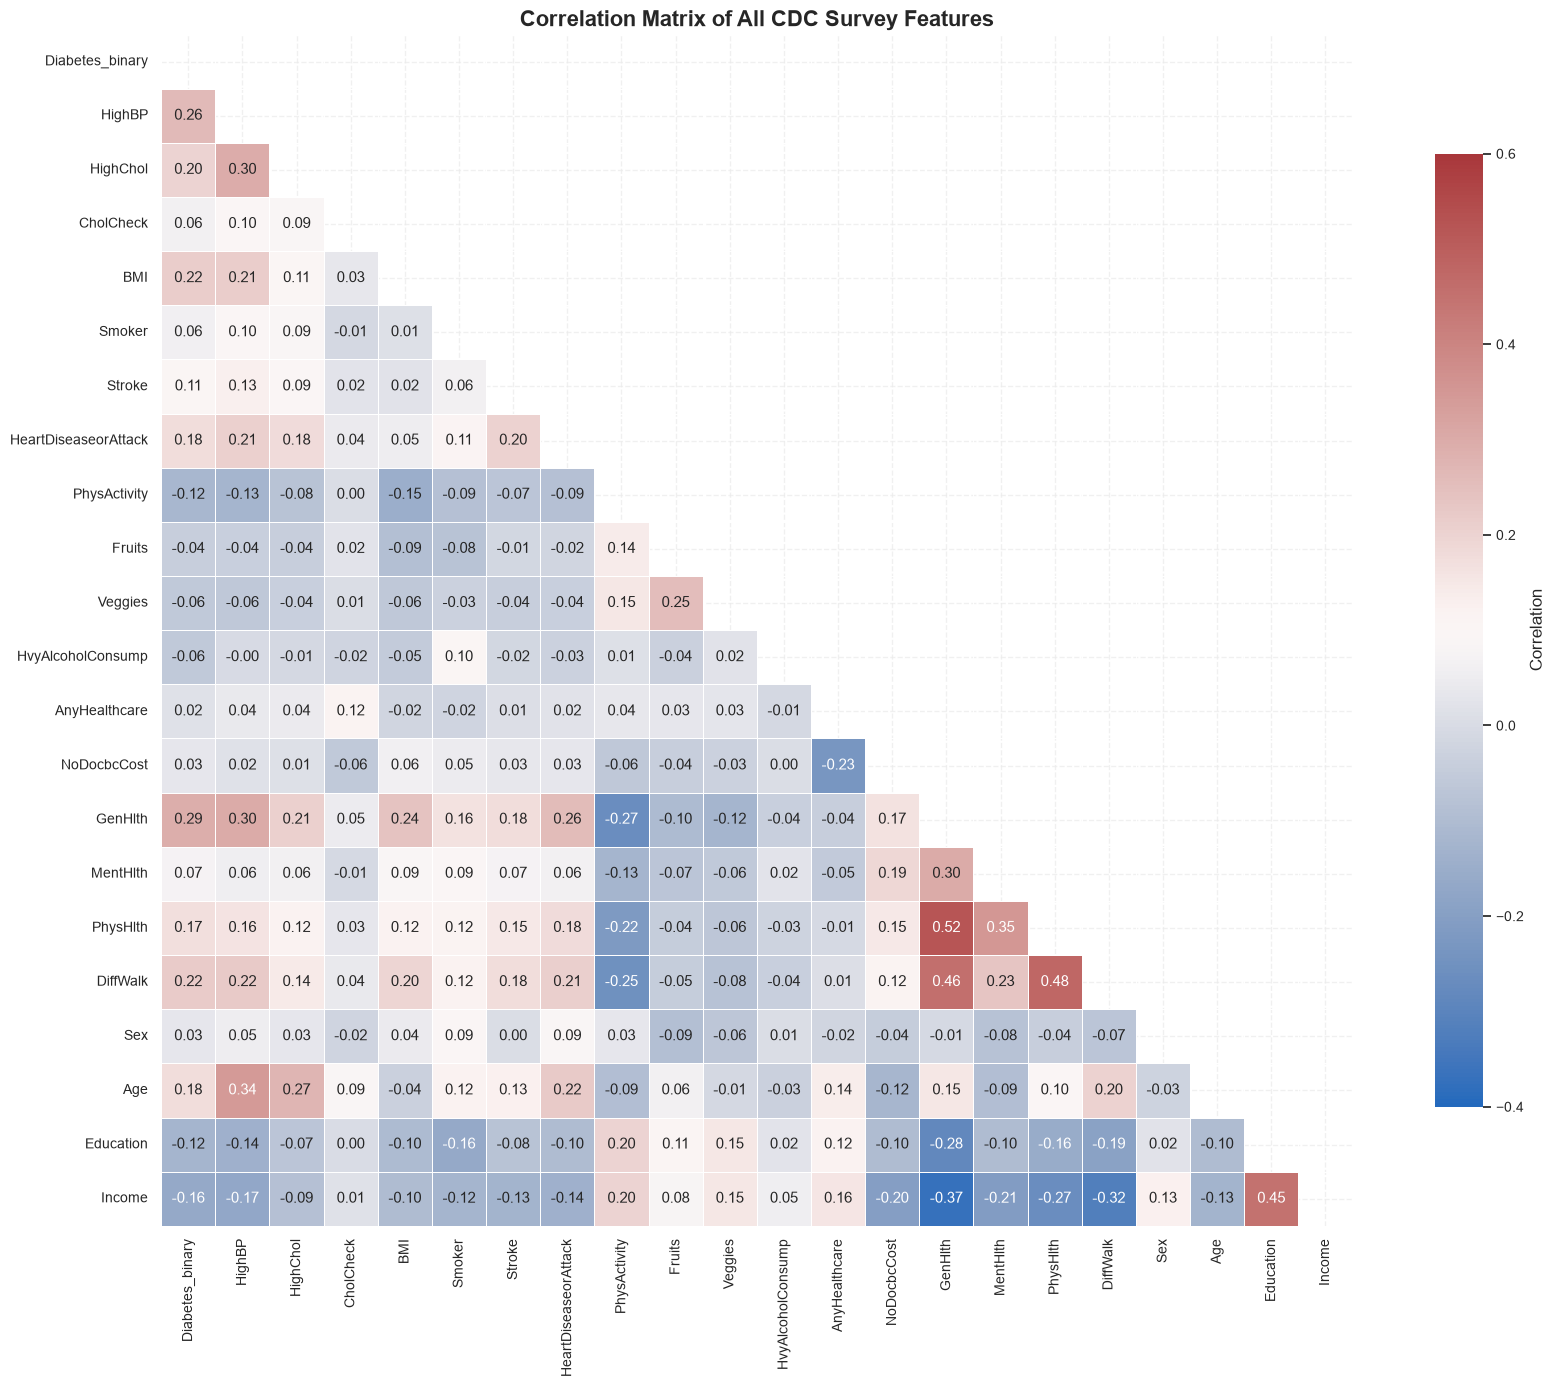

In [26]:
plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-0.4,
    vmax=0.6,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)
plt.title("Correlation Matrix of All CDC Survey Features", fontsize=16, weight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "12_full_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

### 9.3 Collinearity Inspection Among Predictor Variables

Extracting all predictor pairs with $|r| \ge 0.35$ to audit potential collinearity.

In [27]:
# Extract feature pairs with |r| >= 0.35
pairs = []
features = [c for c in df.columns if c not in ["Diabetes_binary", "Comorbidity_Score"]]
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        f1, f2 = features[i], features[j]
        r = corr_matrix.loc[f1, f2]
        if abs(r) >= 0.35:
            pairs.append({"Feature 1": f1, "Feature 2": f2, "Correlation (r)": round(r, 4)})

high_corr_df = pd.DataFrame(pairs).sort_values(by="Correlation (r)", ascending=False)
high_corr_df

,Feature 1,Feature 2,Correlation (r)
0,GenHlth,PhysHlth,0.5244
4,PhysHlth,DiffWalk,0.4784
1,GenHlth,DiffWalk,0.4569
5,Education,Income,0.4491
3,MentHlth,PhysHlth,0.3536
2,GenHlth,Income,-0.3700


---
## 10. Bivariate & Multivariate Deep Dives

We now perform multidimensional cross-tabulations to uncover non-linear interactions:
1. `GenHlth` (1-5) $	imes$ `Age` (1-13) on diabetes risk.
2. `BMI` category $	imes$ `PhysActivity` on diabetes risk.

### 10.1 Interaction Heatmap: General Health Rating vs. Age Group

Cross-tabulating self-reported general health status and age bracket to observe diabetes prevalence rates.

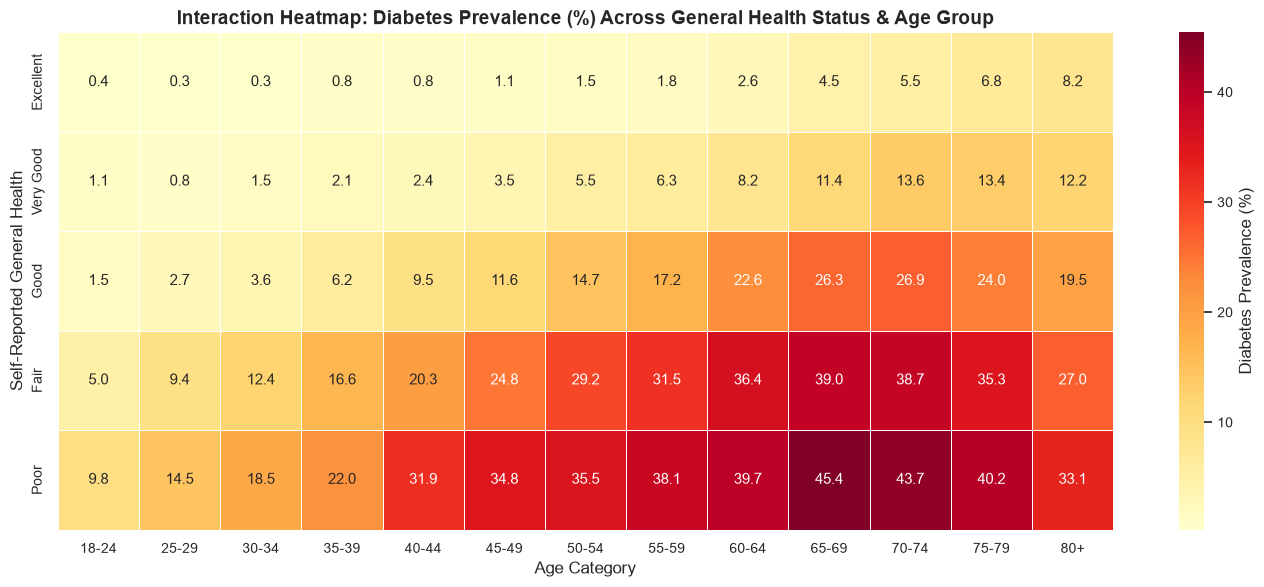

In [28]:
# Pivot table of diabetes prevalence across GenHlth and Age
pivot_gen_age = df.pivot_table(
    index="GenHlth",
    columns="Age",
    values="Diabetes_binary",
    aggfunc="mean"
) * 100

pivot_gen_age.index = [GEN_HLTH_LABELS[i] for i in pivot_gen_age.index]
pivot_gen_age.columns = [AGE_LABELS[i] for i in pivot_gen_age.columns]

plt.figure(figsize=(14, 6))
sns.heatmap(
    pivot_gen_age,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Diabetes Prevalence (%)"},
    linewidths=0.5
)
plt.title("Interaction Heatmap: Diabetes Prevalence (%) Across General Health Status & Age Group", fontsize=14, weight="bold")
plt.xlabel("Age Category")
plt.ylabel("Self-Reported General Health")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "13_genhlth_age_interaction.png", dpi=300, bbox_inches="tight")
plt.show()

### 10.2 Interaction: BMI Categories and Physical Activity

Evaluating how regular physical activity moderates the elevated diabetes risk across BMI categories.

<Figure size 1000x500 with 0 Axes>

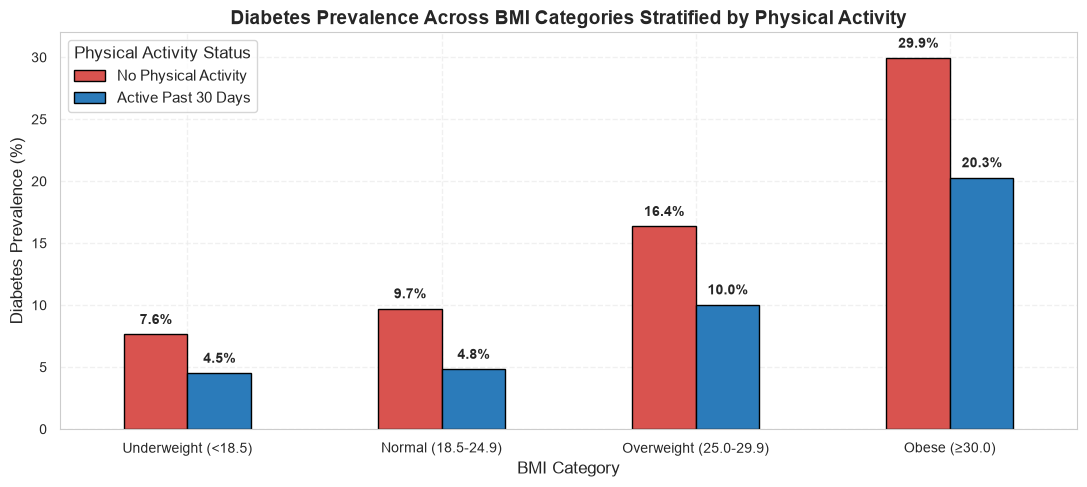

In [29]:
# Define BMI clinical category
def categorize_bmi(bmi):
    if bmi < 18.5:
        return "Underweight (<18.5)"
    elif bmi < 25.0:
        return "Normal (18.5-24.9)"
    elif bmi < 30.0:
        return "Overweight (25.0-29.9)"
    else:
        return "Obese (≥30.0)"

df["BMI_Category"] = df["BMI"].apply(categorize_bmi)
bmi_order = ["Underweight (<18.5)", "Normal (18.5-24.9)", "Overweight (25.0-29.9)", "Obese (≥30.0)"]

bmi_act_agg = df.groupby(["BMI_Category", "PhysActivity"])["Diabetes_binary"].mean().unstack() * 100
bmi_act_agg = bmi_act_agg.reindex(bmi_order)
bmi_act_agg.columns = ["No Physical Activity", "Active Past 30 Days"]

plt.figure(figsize=(10, 5))
ax = bmi_act_agg.plot(
    kind="bar",
    color=["#d9534f", "#2b7bba"],
    edgecolor="black",
    figsize=(11, 5)
)
plt.title("Diabetes Prevalence Across BMI Categories Stratified by Physical Activity", fontsize=14, weight="bold")
plt.xlabel("BMI Category")
plt.ylabel("Diabetes Prevalence (%)")
plt.xticks(rotation=0)
plt.ylim(0, 32)
plt.legend(title="Physical Activity Status")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 0.6),
                ha="center", va="bottom", fontsize=10, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "14_bmi_activity_interaction.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 11. Synthesis of EDA Findings & Preprocessing Roadmap

### 11.1 Executive Summary of Clinical Risk Factors

The table below summarizes the key predictors uncovered in our exploratory analysis ranked by predictive power and clinical impact.

In [30]:
# Summary table of top risk indicators
summary_table = pd.DataFrame([
    {"Rank": 1, "Feature": "GenHlth", "Type": "Ordinal (1-5)", "Correlation": 0.303, "Key Finding": "Strongest single predictor; poor general health corresponds to ~38% diabetes rate vs ~2% for excellent."},
    {"Rank": 2, "Feature": "HighBP", "Type": "Binary", "Correlation": 0.271, "Key Finding": "Over 75% of diabetic individuals suffer from hypertension; Relative Risk = 4.54x."},
    {"Rank": 3, "Feature": "BMI", "Type": "Continuous", "Correlation": 0.224, "Key Finding": "Diabetic median BMI is 31.0 (obese) vs 27.0 for non-diabetic; notable positive skew."},
    {"Rank": 4, "Feature": "DiffWalk", "Type": "Binary", "Correlation": 0.224, "Key Finding": "Difficulty walking is 3.5x more prevalent among diabetic respondents."},
    {"Rank": 5, "Feature": "HighChol", "Type": "Binary", "Correlation": 0.209, "Key Finding": "High cholesterol affects 67% of diabetic individuals vs 38% non-diabetic."},
    {"Rank": 6, "Feature": "Age", "Type": "Ordinal (1-13)", "Correlation": 0.185, "Key Finding": "Monotonic escalation from ~1.5% in ages 18-24 to >22% in ages 65+."},
    {"Rank": 7, "Feature": "HeartDiseaseorAttack", "Type": "Binary", "Correlation": 0.180, "Key Finding": "Cardiovascular event history is 3.1x higher in diabetic cohort."},
    {"Rank": 8, "Feature": "PhysHlth", "Type": "Discrete (0-30)", "Correlation": 0.176, "Key Finding": "Diabetic respondents report 3.1x more physical illness days per month."}
]).set_index("Rank")

summary_table

,Feature,Type,Correlation,Key Finding
Rank,,,,
1,GenHlth,Ordinal (1-5),0.303,Strongest single predictor; poor general health corresponds to ~38% diabetes rate vs ~2% for excellent.
2,HighBP,Binary,0.271,Over 75% of diabetic individuals suffer from hypertension; Relative Risk = 4.54x.
3,BMI,Continuous,0.224,Diabetic median BMI is 31.0 (obese) vs 27.0 for non-diabetic; notable positive skew.
4,DiffWalk,Binary,0.224,Difficulty walking is 3.5x more prevalent among diabetic respondents.
5,HighChol,Binary,0.209,High cholesterol affects 67% of diabetic individuals vs 38% non-diabetic.
6,Age,Ordinal (1-13),0.185,Monotonic escalation from ~1.5% in ages 18-24 to >22% in ages 65+.
7,HeartDiseaseorAttack,Binary,0.180,Cardiovascular event history is 3.1x higher in diabetic cohort.
8,PhysHlth,Discrete (0-30),0.176,Diabetic respondents report 3.1x more physical illness days per month.


### 11.2 Preprocessing & Modeling Strategy for Phase 2

Based on our exploratory findings, the following concrete steps will be implemented in Phase 2:

1. **Stratified Train-Test Splitting**:
   - Split dataset using `StratifiedKFold` or `train_test_split(..., stratify=y)` (e.g. 80% train, 20% test) to strictly maintain the 86:14 ratio in both sets.
2. **Handling Class Imbalance**:
   - Implement algorithmic reweighting (`class_weight='balanced'`) for Logistic Regression, Random Forest, and XGBoost/LightGBM.
   - Evaluate SMOTE / ADASYN oversampling on the training set only to prevent data leakage.
   - Optimize decision threshold based on Precision-Recall curves rather than default 0.5.
3. **Feature Scaling**:
   - `BMI`, `PhysHlth`, and `MentHlth` exhibit positive skewness; apply `RobustScaler` or `StandardScaler`.
4. **Feature Engineering**:
   - `Comorbidity_Index`: Sum of `HighBP`, `HighChol`, `HeartDiseaseorAttack`, `Stroke`.
   - `Obesity_Flag`: Binary indicator for $BMI \ge 30$.
   - `Metabolic_Syndrome_Proxy`: Co-occurrence of $BMI \ge 30$, `HighBP`, and `HighChol`.
5. **Evaluation Metric Framework**:
   - Primary: **PR-AUC (Average Precision)** and **Recall / Sensitivity**.
   - Secondary: **ROC-AUC** and **F1-Score**.

In [31]:
# Verify environment and readiness for Phase 2
clean_export_path = Path("../data/processed")
clean_export_path.mkdir(parents=True, exist_ok=True)
print(f"Data directory validated and ready for Phase 2: {clean_export_path.resolve()}")
print("Phase 1 Exploratory Data Analysis complete!")

Data directory validated and ready for Phase 2: D:\Projects\DiabetesPrediction_CDC\data\processed
Phase 1 Exploratory Data Analysis complete!
